# IIA - Trabajo Práctico 3 - Redes Neuronales

In [4]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import sklearn as skl
from sklearn.neural_network import MLPRegressor
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import mean_squared_error, zero_one_loss

from time import sleep

from copy import deepcopy

# Explorando las Redes

In [2]:
# Parámetros
"""
Comenzar y frenar el entrenamiento de una red es costoso, por lo que no
mediremos las métricas una vez por época, sino que haremos varias épocas a la
vez. Por ésto definimos sub-épocas, por ejemplo como 10, para realizar 10 épocas
a la vez y luego medir las métricas de error.
"""
sub_epocas = 25   # numero de epocas que entrena cada vez
super_epocas = 100 # numero de veces que realizaremos sub-epocas
# epocas ~= sub_epocas * super_epocas
eta = 0.01        # learning rate
alfa = 0.9        # momentum
N2 = 60            # neuronas en la capa oculta

## Anotaciones:
Época =  Es una pasada completa del algoritmo de entrenamiento sobre todo el conjunto de datos de entrenamiento. El modelo procesa todos los ejemplos del conjunto de entrenamiento una vez y actualiza los pesos 

In [5]:
from typing import Tuple
def espirales(n: int) -> Tuple[np.ndarray, np.ndarray]:
    half = n // 2
    X0, X1 = [], []

    while len(X0) < half or len(X1) < half:
        x = np.random.uniform(-1, 1)
        yc = np.random.uniform(-1, 1)

        r = np.sqrt(x**2 + yc**2)
        if r > 1 or r == 0:
            continue

        # theta base en [0, 2*pi)
        theta = np.arctan2(yc, x) % (2 * np.pi)

        # Probamos theta y theta + 2*pi (segunda vuelta)
        # En cuál de las dos vueltas cae el punto según su r
        in_band = False
        for k in range(-1,3):  # hasta 3 vueltas
            t = theta + 2 * np.pi * k
            rho_low  = t / (4 * np.pi)
            rho_high = (t + np.pi) / (4 * np.pi)
            if rho_low <= r <= rho_high:
                in_band = True
                break

        label = 0 if in_band else 1

        if label == 0 and len(X0) < half:
            X0.append([x, yc])
        elif label == 1 and len(X1) < half:
            X1.append([x, yc])

    X = np.array(X0 + X1)
    y = np.hstack([np.zeros(half), np.ones(half)])
    return X, y


## Definimos nuestras redes


In [6]:
# Defino MLP para regresión
regr = MLPRegressor(
    hidden_layer_sizes=(N2,), activation='logistic', solver='sgd', alpha=0.0,
    batch_size=1, learning_rate='constant', learning_rate_init=eta,
    momentum=alfa, nesterovs_momentum=False, tol=0.0, warm_start=True,
    max_iter=sub_epocas
)

print(regr)

MLPRegressor(activation='logistic', alpha=0.0, batch_size=1,
             hidden_layer_sizes=(60,), learning_rate_init=0.01, max_iter=25,
             nesterovs_momentum=False, solver='sgd', tol=0.0, warm_start=True)


In [7]:
# Defino MLP para clasificación
clasif = MLPClassifier(
    hidden_layer_sizes=(N2,), activation='logistic', solver='sgd', alpha=0.0,
    batch_size=1, learning_rate='constant', learning_rate_init=eta,
    momentum=alfa, nesterovs_momentum=False, tol=0.0, warm_start=True,
    max_iter=sub_epocas
)

print(clasif)

MLPClassifier(activation='logistic', alpha=0.0, batch_size=1,
              hidden_layer_sizes=(60,), learning_rate_init=0.01, max_iter=25,
              nesterovs_momentum=False, solver='sgd', tol=0.0, warm_start=True)


## Entrenamos

> **Warning**: el entrenamiento de las redes es computacionalmente pesado. Algunos de los entrenamientos que se plantean en el trabajo llevan varios minutos, dependiendo de la velocidad del procesador. El tiempo máximo en Google Colab fue de alrededor de 10 minutos. Tengan eso en cuenta para hacer el trabajo.



In [8]:
def cargar_csv(path, xcols=2):
    """
    Argumentos:
      path (str): ruta al archivo csv a cargar
      xcols (int): cantidad de columnas que representan las entradas,
        la columna restante representara la clase o dato de salida
    """
    df = pd.read_csv(path, header=None)
    X = df.loc[:, 0:(xcols-1)]
    y = df.loc[:, xcols]
    return X,y

In [9]:
def entrenar_red(red, evaluaciones,
                 X_train, y_train,
                 X_val,   y_val,
                 X_test,  y_test):
    """
    Función que entrena una red ya definida previamente "evaluaciones" veces,
    cada vez entrenando un número de épocas elegido al crear la red y midiendo
    el error en train, validación y test al terminar ese paso de entrenamiento.
    Guarda y devuelve la red en el paso de evaluación que da el mínimo error de
    validación.

    Argumentos:
      red: red neuronal predefinida
      evaluaciones (int): las veces que evalua
      X_{}: los conjuntos de valores de entrada de train, validación y test
      y_{}: los conjuntos de valores de salida o clase

    X_train
      La red aprende de él
      Los ejercicios de práctica
    X_val
      Evalúa durante el entrenamiento
      Los simulacros de examen
    X_test
      Evaluación final imparcial
      El examen real

    Salidas:
      best_red: la red entrenada en el mínimo de validación
      error_{}: los errores de: train, validación y test medidos en cada
        evaluación
    """
    error_train = []
    error_val = []
    error_test = []
    best_val = 1.0
    best_red = red
    # Evaluaciones es 100
    for epoch in range(evaluaciones):
      # red.partial_fit(X_train, y_train, classes=[0,1])
      ## Podríamos llamar partial_fit para realizar una sóla pasada a la vez,
      ## pero al ser muy costoso frenar y reanudar el entrenamiento realizamos
      ## varias épocas a la vez. Recordemos que la red fue definida con el
      ## parámetro 'sub-epocas', con lo cual cada llamado a 'fit' realiza esa
      ## cantidad de épocas
      red.fit(X_train, y_train)
      # El fit este pasa los datos 25 veces por la red (sub_epocas veces)
      # error de training
      y_pred_train = red.predict(X_train)
      error_train.append(zero_one_loss(y_train, y_pred_train))
      # error de validacion
      y_pred_val = red.predict(X_val)
      cur_val = zero_one_loss(y_val, y_pred_val)
      error_val.append(cur_val)
      # error de test
      error_test.append(1 - red.score(X_test, y_test))
      if best_val > cur_val:
        best_val = cur_val
        best_red = deepcopy(red)
    return best_red, error_train, error_val, error_test

In [10]:
# Cargamos los datos...
X, y = cargar_csv('xor.csv')

# Hacemos el split de training y testing
X2, X_test, y2, y_test = skl.model_selection.train_test_split(
    X, y, test_size=0.2)  # para xor de 200 me quedan 40 de test

# y spliteamos el training en training y validacion
X_train, X_val, y_train, y_val = skl.model_selection.train_test_split(
    X2, y2, test_size=0.2)  # para xor de 160 me quedan 32 de val

# Corremos el entrenamiento
clasif, e_train, e_val, e_test = entrenar_red(
    clasif, super_epocas, X_train, y_train, X_val, y_val, X_test, y_test)

C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (25) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (25) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (25) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppD

## Ploteamos Algunas Métricas

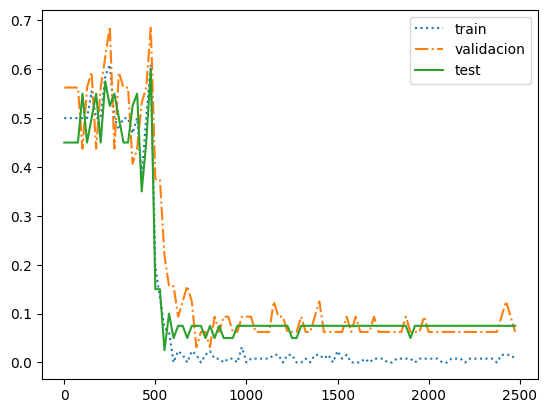

In [11]:
rango = np.array(range(super_epocas)) * sub_epocas
plt.plot(rango, e_train, label="train", linestyle=":")
plt.plot(rango, e_val, label="validacion", linestyle="-.")
plt.plot(rango, e_test, label="test", linestyle="-")
plt.legend()
plt.show()

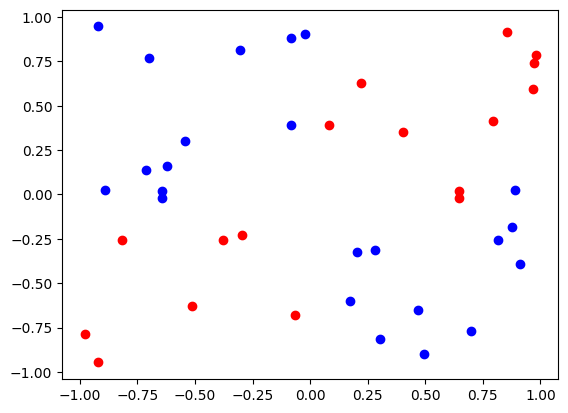

In [12]:
y_out = clasif.predict(X_test)
X_out = X_test.copy()
X_out[2] = y_out

# diferenciar entre clase 0 y clase 1
c0 = X_out.loc[X_out[2] == 0]
c1 = X_out.loc[X_out[2] == 1]

xs0 = c0[0].values.tolist()
ys0 = c0[1].values.tolist()

xs1 = c1[0].values.tolist()
ys1 = c1[1].values.tolist()

plt.scatter(xs0, ys0, color='red')
plt.scatter(xs1, ys1, color='blue')
plt.show()

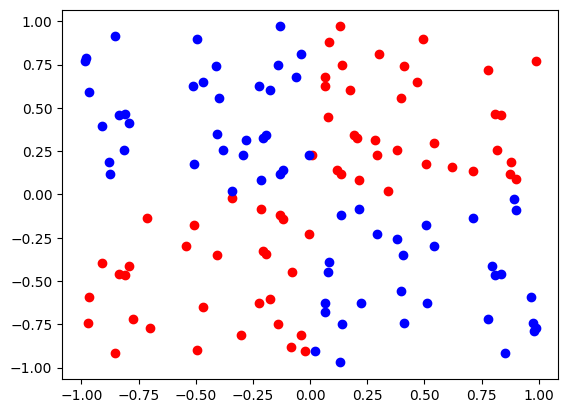

In [13]:
# diferenciar entre clase 0 y clase 1
Xt = X_train.copy()
Xt[2] = y_train
c0 = Xt.loc[Xt[2] == 0]
c1 = Xt.loc[Xt[2] == 1]

xs0 = c0[0].values.tolist()
ys0 = c0[1].values.tolist()

xs1 = c1[0].values.tolist()
ys1 = c1[1].values.tolist()

plt.scatter(xs0, ys0, color='red')
plt.scatter(xs1, ys1, color='blue')
plt.show()

# Ejercicio 1. Capacidad de Modelado.

C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


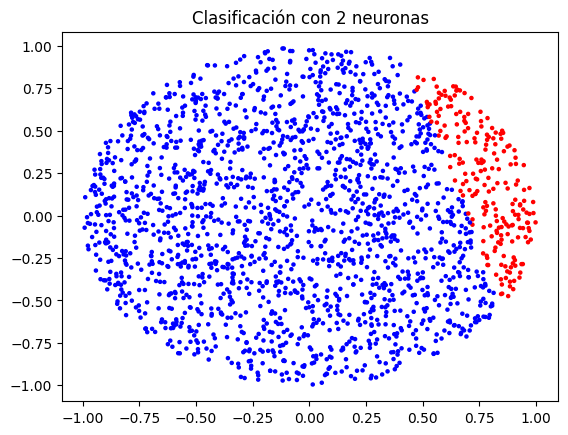

C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


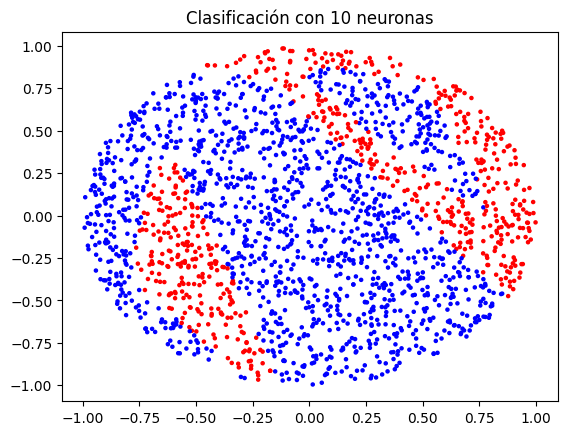

C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppD

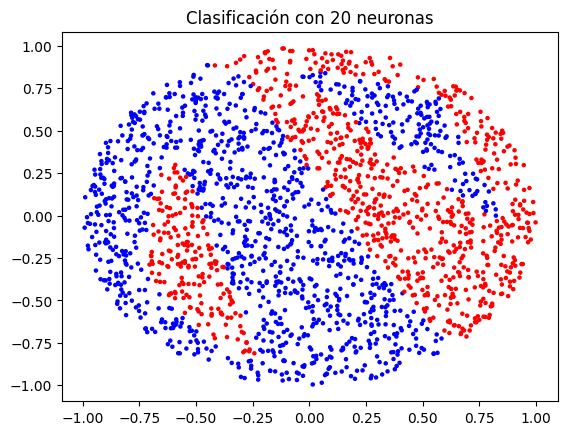

C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppD

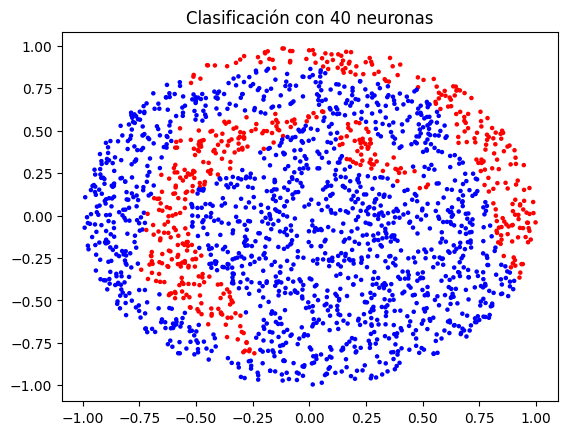

In [14]:
# Cargamos los datos...
X_ajuste, y_ajuste = espirales(600)   # los 600 para ajustar
X_test,   y_test   = espirales(2000)  # los 2000 de test
# 2. Dividir los 600 en train (80%) y val (20%)
X_train, X_val, y_train, y_val = skl.model_selection.train_test_split(
    X_ajuste, y_ajuste, test_size=0.2
)

eta  = 0.1
alfa = 0.9
evaluaciones = 1000
sub_epocas   = 20

for N2 in [2, 10, 20, 40]:
    red = MLPClassifier(
        hidden_layer_sizes=(N2,), activation='logistic', solver='sgd', alpha=0.0,
        batch_size=1, learning_rate='constant', learning_rate_init=eta,
        momentum=alfa, nesterovs_momentum=False, tol=0.0, warm_start=True,
        max_iter=sub_epocas
    )
    # Corremos el entrenamiento
    redDeMenorError, e_train, e_val, e_test = entrenar_red(
        red, evaluaciones, X_train, y_train, X_val, y_val, X_test, y_test)
    y_pred = redDeMenorError.predict(X_test)
    
    plt.figure()
    plt.scatter(X_test[:, 0], X_test[:, 1], c=y_pred, cmap='bwr', s=5)
    plt.title(f'Clasificación con {N2} neuronas')
    plt.show()    



In [ ]:
# Cargamos los datos...
X_ajuste, y_ajuste = espirales(600)   # los 600 para ajustar
X_test,   y_test   = espirales(2000)  # los 2000 de test
# 2. Dividir los 600 en train (80%) y val (20%)
X_train, X_val, y_train, y_val = skl.model_selection.train_test_split(
    X_ajuste, y_ajuste, test_size=0.2
)

eta  = 0.1
alfa = 0.9
evaluaciones = 1000
sub_epocas   = 20

red = MLPClassifier(
  hidden_layer_sizes=(200,), activation='logistic', solver='sgd', alpha=0.0,
  batch_size=1, learning_rate='constant', learning_rate_init=eta,
  momentum=alfa, nesterovs_momentum=False, tol=0.0, warm_start=True,
  max_iter=sub_epocas
)
# Corremos el entrenamiento
redDeMenorError, e_train, e_val, e_test = entrenar_red(
  red, evaluaciones, X_train, y_train, X_val, y_val, X_test, y_test)
y_pred = redDeMenorError.predict(X_test)

plt.figure()
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_pred, cmap='bwr', s=5)
plt.title(f'Clasificación con 200 neuronas')
plt.show()  

C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppD

## Conclusiones Ejercicio 1:

# Ejercicio 2. Mínimos Locales.

In [ ]:
# Cargamos los datos...
X_ajuste, y_ajuste = cargar_csv('dos_elipses.data')

X_500, _, y_500, _ = skl.model_selection.train_test_split(
    X_ajuste, y_ajuste, train_size=500
)

X_train, X_val, y_train, y_val = skl.model_selection.train_test_split(
    X_500, y_500, test_size=0.2
)

X_test, y_test = cargar_csv('dos_elipses.test')


N2 = 6
evaluaciones = 300
sub_epocas   = 50


In [ ]:
resultados = []  # guardará (eta, alfa, error_promedio)

best_curves = None
best_error = float('inf')
best_params = (None, None)

for eta in [0.1, 0.01, 0.001]:
    for alfa in [0, 0.5, 0.9]:
        errores_test = []
        ultimas_curvas = None  # Guarda las curvas del último run

        for i in range(10):
            red = MLPClassifier(
                hidden_layer_sizes=(N2,), activation='logistic', solver='sgd', alpha=0.0,
                batch_size=1, learning_rate='constant', learning_rate_init=eta,
                momentum=alfa, nesterovs_momentum=False, tol=0.0, warm_start=True,
                max_iter=sub_epocas
            )
            # Corremos el entrenamiento
            mejor_red, e_train, e_val, e_test = entrenar_red(
                red, evaluaciones, X_train, y_train, X_val, y_val, X_test, y_test)
            
            # Error de test de la mejor red (la del mínimo de validación)
            error = zero_one_loss(y_test, mejor_red.predict(X_test))
            errores_test.append(error)
            
            # Para calcular las gráficas
            ultimas_curvas = (e_train, e_val, e_test)
            
            print(f"Entrenamiento {i}/10 para eta={eta} y alfa={alfa}")

            
        promedio = np.mean(errores_test)
        resultados.append((eta, alfa, promedio))
        
        if promedio < best_error:
            best_error = promedio
            best_curves = ultimas_curvas
            best_params = (eta, alfa)



       eta     alfa error_test_medio
--------------------------------------
       0.1        0           0.2634
       0.1      0.5           0.2334
       0.1      0.9           0.2783
      0.01        0           0.4421
      0.01      0.5           0.4437
      0.01      0.9           0.2528
     0.001        0           0.4485
     0.001      0.5           0.4431
     0.001      0.9           0.4422


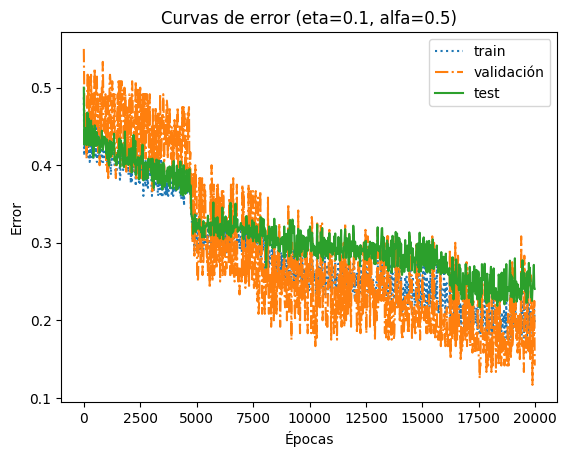

In [18]:
# Tabla
print("\n{:>10} {:>8} {:>16}".format("eta", "alfa", "error_test_medio"))
print("-" * 38)
for eta, alfa, err in resultados:
    print(f"{eta:>10} {alfa:>8} {err:>16.4f}")
    
    
# Valores seleccionados    
e_train, e_val, e_test = best_curves
rango = np.array(range(evaluaciones)) * sub_epocas

plt.plot(rango, e_train, label="train",      linestyle=":")
plt.plot(rango, e_val,   label="validación", linestyle="-.")
plt.plot(rango, e_test,  label="test",       linestyle="-")
plt.xlabel("Épocas")
plt.ylabel("Error")
plt.title(f"Curvas de error (eta={best_params[0]}, alfa={best_params[1]})")
plt.legend()
plt.show()

In [ ]:
# PARA GUARDAR RESULTADOS
import pickle

to_save = {
    'resultados':  resultados,
    'best_curves': best_curves,
    'best_params': best_params,
}

with open('ej2_resultados.pkl', 'wb') as f:
    pickle.dump(to_save, f)

print("Guardado correctamente en 'ej2_resultados.pkl'")

Guardado correctamente en 'ej2_resultados.pkl'


In [ ]:
# PARA CARGAR RESULTADOS
import pickle

with open('ej2_resultados.pkl', 'rb') as f:
    data = pickle.load(f)

resultados  = data['resultados']
best_curves = data['best_curves']
best_params = data['best_params']

print("Cargado correctamente")
print(resultados)

# Ejercicio 3. Regularización

# Ejercicio 4. Regularización (2).

# Ejercicio 5. Dimensionalidad.

# (OPCIONAL) Ejercicio 6. Multiclase.

# (OPCIONAL) Ejercicio 7. Minibatch.